# Setup

In [1]:
from time import perf_counter
from contextlib import contextmanager

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from IPython.display import display

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE = "#2a78d6", "#eb6834"
timing_records = []
run_origin = perf_counter()

@contextmanager
def measure(section, step, rows):
    start = perf_counter()
    try:
        yield
    except Exception:
        raise
    else:
        timing_records[:] = [r for r in timing_records
                             if (r["section"], r["step"]) != (section, step)]
        timing_records.append({
            "section": section, "step": step, "rows": rows,
            "start_s": start - run_origin,
            "duration_s": perf_counter() - start,
        })

In [2]:
def show_quality_chart(fig, title, x_title, y_title, height=440):
    title = title.replace(" · ", "<br><sup>", 1) + ("</sup>" if " · " in title else "")
    fig.update_layout(
        title=dict(text=title, font=dict(size=17)),
        xaxis_title=x_title, yaxis_title=y_title,
        template="plotly_white", height=height,
        margin=dict(l=80, r=45, t=115, b=80),
        font=dict(size=12, color="#242424"),
        paper_bgcolor="#fcfcfb", plot_bgcolor="#fcfcfb",
        hovermode="closest", bargap=0.55,
        updatemenus=[dict(type="buttons", direction="right", x=1, xanchor="right", y=1.17,
            buttons=[
                dict(label="Terang", method="relayout", args=[{
                    "template": "plotly_white", "paper_bgcolor": "#fcfcfb",
                    "plot_bgcolor": "#fcfcfb", "font.color": "#242424",
                    "xaxis.gridcolor": "#e5e5e3", "yaxis.gridcolor": "#e5e5e3",
                }]),
                dict(label="Gelap", method="relayout", args=[{
                    "template": "plotly_dark", "paper_bgcolor": "#1a1a19",
                    "plot_bgcolor": "#1a1a19", "font.color": "#eeeeec",
                    "xaxis.gridcolor": "#353534", "yaxis.gridcolor": "#353534",
                }]),
            ])],
    )
    fig.update_xaxes(automargin=True)
    fig.update_yaxes(automargin=True)
    fig.show(config={"displaylogo": False, "responsive": True})

In [32]:
train_source = "https://media.githubusercontent.com/media/NuriInformatics/detect-mitigate-nyctaxi/refs/heads/main/data/train.csv"
test_source = "https://media.githubusercontent.com/media/NuriInformatics/detect-mitigate-nyctaxi/refs/heads/main/data/test.csv"
df_raw = pd.read_csv(train_source)
df_test = pd.read_csv(test_source)
original_columns = df_raw.columns.tolist()
df = df_raw.copy()
print("Train:", df.shape, "Test:", df_test.shape)

Train: (1458644, 11) Test: (625134, 9)


# 1. Inconsistent formatting
Mencari data yang bernilai sama tetapi dengan format berbeda atau tidak konsisten contohnya 'pickup_datetime' dan 'dropoff_datetime'

In [4]:
with measure("1. Formatting", "Parsing dan normalisasi", len(df)):
    parsed_datetime_pd = pd.to_datetime(
        df_raw["pickup_datetime"], format="%Y-%m-%d %H:%M:%S", errors="coerce"
    )
    parsed_datetime_dd = pd.to_datetime(
        df_raw["dropoff_datetime"], format="%Y-%m-%d %H:%M:%S", errors="coerce"
    )
    format_errors = pd.Series({
        "pickup gagal parse": (df_raw["pickup_datetime"].notna() & parsed_datetime_pd.isna()).sum(),
        "dropoff gagal parse": (df_raw["dropoff_datetime"].notna() & parsed_datetime_dd.isna()).sum(),
        "flag di luar N/Y": (~df_raw["store_and_fwd_flag"].isin(["N", "Y"])
                              & df_raw["store_and_fwd_flag"].notna()).sum(),
    })
    df["pickup_datetime"] = parsed_datetime_pd
    df["dropoff_datetime"] = parsed_datetime_dd
    format_failure = (
        (df_raw["pickup_datetime"].notna() & parsed_datetime_pd.isna())
        | (df_raw["dropoff_datetime"].notna() & parsed_datetime_dd.isna())
        | (~df_raw["store_and_fwd_flag"].isin(["N", "Y"])
           & df_raw["store_and_fwd_flag"].notna())
    )
display(format_errors.to_frame("jumlah"))
display(df_raw["store_and_fwd_flag"].value_counts(dropna=False).to_frame("jumlah"))
print("Mitigasi: dua kolom tanggal dinormalisasi; data mentah tetap tersedia.")

,jumlah
pickup gagal parse,0
dropoff gagal parse,0
flag di luar N/Y,0


,jumlah
store_and_fwd_flag,
N,1450599
Y,8045


Mitigasi: dua kolom tanggal dinormalisasi; data mentah tetap tersedia.


Dari hasil diatas inconsistent pada tanggal sudah aman tidak ada yang berbeda. kegunaan check disana adalah kalau ada yang berbeeda format akan terlihat

# 2. Erroneous data
adalah nilai yang tidak masuk akal atau tidak mungkin terjadi. Contohnya :
- passenger_count yang tidak mungkin bernilai negatif passenger_count < 0
- trip_duration yang negatif dibawah 0,
- koordinat yang diluar radius bumi

In [5]:
with measure("2. Erroneous", "Validasi domain", len(df)):
    coordinate_columns = ["pickup_longitude", "dropoff_longitude", "pickup_latitude", "dropoff_latitude"]
    invalid_geo = (
        (df["pickup_longitude"].notna() & ~df["pickup_longitude"].between(-180, 180))
        | (df["dropoff_longitude"].notna() & ~df["dropoff_longitude"].between(-180, 180))
        | (df["pickup_latitude"].notna() & ~df["pickup_latitude"].between(-90, 90))
        | (df["dropoff_latitude"].notna() & ~df["dropoff_latitude"].between(-90, 90))
    )
    invalid_duration = df["trip_duration"].notna() & (df["trip_duration"] <= 0)
    invalid_passengers = df["passenger_count"].notna() & (
        (df["passenger_count"] < 0) | (df["passenger_count"] % 1 != 0)
    )
    domain_invalid = invalid_geo | invalid_duration | invalid_passengers
    passenger_review = df["passenger_count"].eq(0)
    erroneous_summary = pd.Series({
        "Durasi <= 0": invalid_duration.sum(),
        "Koordinat di luar rentang bumi": invalid_geo.sum(),
        "Penumpang negatif/noninteger": invalid_passengers.sum(),
        "Penumpang nol (perlu verifikasi, tidak otomatis invalid)": passenger_review.sum(),
    })
display(erroneous_summary.to_frame("jumlah"))

,jumlah
Durasi <= 0,0
Koordinat di luar rentang bumi,0
Penumpang negatif/noninteger,0
"Penumpang nol (perlu verifikasi, tidak otomatis invalid)",60


### Interpretasi dan mitigasi domain

Koordinat di luar rentang bumi, durasi nonpositif, dan jumlah penumpang negatif/noninteger melanggar aturan domain. Penumpang nol hanya ditandai untuk verifikasi; batas kapasitas tidak ditebak. Nilai kosong diperiksa di bagian Missing values.

Record invalid atau gagal parsing diberi flag, dikeluarkan dari salinan analisis, dan disimpan di `excluded_invalid`, tanpa menebak nilai pengganti. Semua record tetap ada di `df_raw`.

In [33]:
with measure("2. Erroneous", "Flag domain dan salinan analisis", len(df)):
    excluded_invalid = df.loc[domain_invalid | format_failure].copy()
    excluded_invalid["reason"] = np.where(
        domain_invalid.loc[excluded_invalid.index], "Pelanggaran domain", "Gagal validasi format"
    )
    df = df.loc[~(domain_invalid | format_failure)].copy()
    df["passenger_review_flag"] = df["passenger_count"].eq(0)
print("Record berflag domain/format yang dikeluarkan:", len(excluded_invalid))


Record berflag domain/format yang dikeluarkan: 0


Berdasarkan hasil check kordinat semua data berada pada rentan radius bumi..

### Pemeriksaan kombinasi jarak–durasi
Koordinat valid secara domain belum menjamin perjalanan masuk akal. Gunakan haversine sebagai perpindahan garis lurus; kecepatan yang dihitung adalah estimasi minimum kecepatan rata-rata rute. Tampilkan nilai tertinggi dan cocokkan durasi dengan timestamp. Nilai rendah tidak membuktikan kesalahan; nilai sangat tinggi mengindikasikan masalah lokasi/waktu, bukan otomatis noise GPS.

In [7]:
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = (np.sin((lat2 - lat1) / 2) ** 2
         + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2)
    return 2 * 6371.0 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

In [8]:
with measure("2. Erroneous", "Konsistensi waktu dan haversine", len(df)):
    df["duration_from_time"] = (df["dropoff_datetime"] - df["pickup_datetime"]).dt.total_seconds()
    comparable = df[["trip_duration", "duration_from_time"]].notna().all(axis=1)
    df["duration_mismatch_flag"] = comparable & df["trip_duration"].ne(df["duration_from_time"])
    df["distance_km"] = haversine_km(
        df["pickup_latitude"], df["pickup_longitude"],
        df["dropoff_latitude"], df["dropoff_longitude"],
    )
    df["avg_speed_kmh"] = df["distance_km"] / (df["trip_duration"] / 3600)
    speed_review_limit = 150
    speed_candidates = df.loc[df["avg_speed_kmh"].gt(speed_review_limit), [
        "id", "pickup_datetime", "dropoff_datetime", "trip_duration", "duration_from_time",
        *coordinate_columns, "distance_km", "avg_speed_kmh",
    ]].sort_values("avg_speed_kmh", ascending=False)
    speed_sensitivity = pd.DataFrame({"batas_kmh": [150, 200, 300, 500, 1000]})
    speed_sensitivity["jumlah_di_atas_batas"] = [
        int(df["avg_speed_kmh"].gt(limit).sum()) for limit in speed_sensitivity["batas_kmh"]
    ]
print("Durasi berbeda dari timestamp:", int(df["duration_mismatch_flag"].sum()))
print("Tidak dapat dibandingkan:", int((~comparable).sum()))
print("Seluruh kandidat >150 km/jam; tabel tidak dipotong:")
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(speed_candidates.round({"distance_km": 4, "avg_speed_kmh": 1}))
display(speed_sensitivity)

Durasi berbeda dari timestamp: 0
Tidak dapat dibandingkan: 0
Seluruh kandidat >150 km/jam; tabel tidak dipotong:


,id,pickup_datetime,dropoff_datetime,trip_duration,duration_from_time,pickup_longitude,dropoff_longitude,pickup_latitude,dropoff_latitude,distance_km,avg_speed_kmh
1176337,id3619353,2016-02-13 20:28:30,2016-02-13 20:28:37,7,7.0,-73.936974,-73.789848,40.764610,40.646858,18.0344,9274.8
910072,id1146400,2016-02-15 18:57:32,2016-02-15 19:02:35,303,303.0,-73.989914,-70.346077,40.756634,36.398121,578.8428,6877.3
184925,id2306955,2016-05-07 18:58:53,2016-05-07 19:12:05,792,792.0,-72.809669,-73.987228,51.881084,40.750599,1240.9087,5640.5
974378,id1510552,2016-01-06 20:40:52,2016-01-06 20:51:03,611,611.0,-71.799896,-79.352837,35.081532,40.436329,891.2141,5251.0
377068,id0116374,2016-04-02 20:33:19,2016-04-02 20:38:01,282,282.0,-74.007095,-76.963242,40.717113,38.946033,320.1258,4086.7
1013474,id3626673,2016-05-05 18:02:50,2016-05-05 18:18:23,933,933.0,-73.978912,-79.338699,40.756763,41.427902,455.2412,1756.6
923793,id1001696,2016-02-24 21:02:32,2016-02-24 21:25:57,1405,1405.0,-73.972366,-79.553535,40.758633,43.674000,562.2352,1440.6
1001028,id1653963,2016-06-12 06:35:13,2016-06-12 06:35:15,2,2.0,-73.922890,-73.925850,40.858200,40.851521,0.7833,1410.0
906281,id1935555,2016-06-19 20:18:35,2016-06-19 20:19:26,51,51.0,-73.781860,-73.993690,40.644657,40.724537,19.9482,1408.1
595540,id1723416,2016-03-20 21:07:56,2016-03-20 21:12:35,279,279.0,-78.547401,-79.786133,40.817131,40.917637,104.7600,1351.7


,batas_kmh,jumlah_di_atas_batas
0,150,98
1,200,68
2,300,42
3,500,30
4,1000,15


### Visualisasi jarak–durasi dan sensitivitas ambang
Scatter memakai sampel tetap maksimum 30.000 trip sebagai konteks, ditambah seluruh kandidat >150 km/jam. Kedua sumbu log hanya mencakup jarak dan durasi positif; perpindahan nol tetap dihitung terpisah. Garis 150 km/jam adalah batas tinjauan, bukan batas benar–salah.

In [9]:
with measure("2. Erroneous", "Sampel visualisasi jarak durasi", len(df)):
    scatter_pool = df.loc[df["distance_km"].gt(0) & df["trip_duration"].gt(0),
                          ["id", "trip_duration", "distance_km", "avg_speed_kmh"]]
    scatter_data = pd.concat([
        scatter_pool.sample(n=min(30000, len(scatter_pool)), random_state=42),
        scatter_pool.loc[scatter_pool["avg_speed_kmh"].gt(speed_review_limit)],
    ]).loc[lambda values: ~values.index.duplicated()]
    scatter_audit = pd.Series({
        "Trip sebelum seleksi kecepatan": len(df),
        "Trip berjarak nol, di luar scatter log": int(df["distance_km"].eq(0).sum()),
        "Titik ditampilkan (sampel + semua kandidat)": len(scatter_data),
    }, name="jumlah")
display(scatter_audit.to_frame())

,jumlah
Trip sebelum seleksi kecepatan,1458644
"Trip berjarak nol, di luar scatter log",5897
Titik ditampilkan (sampel + semua kandidat),30097


In [10]:
fig = go.Figure(go.Scattergl(
    x=scatter_data["trip_duration"], y=scatter_data["distance_km"], mode="markers",
    marker=dict(color=BLUE, size=8, opacity=0.4),
    customdata=scatter_data[["id", "avg_speed_kmh"]].to_numpy(),
    hovertemplate="%{customdata[0]}<br>Durasi %{x:,.0f} s<br>Jarak %{y:.4f} km"
                  "<br>Kecepatan %{customdata[1]:.1f} km/jam<extra></extra>",
))
if len(scatter_data):
    line_x = np.array([scatter_data["trip_duration"].min(), scatter_data["trip_duration"].max()])
    fig.add_shape(type="line", x0=line_x[0], x1=line_x[1],
                  y0=line_x[0] * speed_review_limit / 3600,
                  y1=line_x[1] * speed_review_limit / 3600,
                  line=dict(color="#777777", width=2, dash="dash"))
    fig.add_annotation(x=0.99, y=0.98, xref="paper", yref="paper", xanchor="right",
                       text="Garis putus-putus: flag tinjauan >150 km/jam", showarrow=False)
fig.update_xaxes(type="log")
fig.update_yaxes(type="log")
show_quality_chart(fig, "Jarak–durasi dan flag kecepatan · sampel + seluruh kandidat",
                   "Durasi (detik, log)", "Perpindahan Haversine (km, log)")

### Cara membaca grafik
Setiap titik adalah satu trip. Ke kanan durasi makin lama; ke atas perpindahan makin jauh. Kedua sumbu log: langkah utama 1, 10, 100, dan 1.000 berarti kenaikan sepuluh kali, bukan penambahan tetap.

Garis putus-putus memenuhi `jarak = 150 × durasi / 3600`. Contoh: 100 detik dengan perpindahan 4,17 km berada pada garis. Titik di atas garis menghasilkan kecepatan >150 km/jam dan diberi flag tinjauan; titik di bawahnya belum tentu valid. Pola utama menunjukkan perjalanan lebih jauh cenderung memerlukan waktu lebih lama. Titik jauh di kanan tetapi rendah menunjukkan durasi lama dengan perpindahan pendek, yang perlu ditinjau terpisah.

Grafik mencakup sampel konteks dan seluruh kandidat sebelum seleksi kecepatan, bukan kepadatan seluruh dataset. **Flag tidak membuktikan GPS drift.** Keputusan pengeluaran record dijelaskan setelah pemeriksaan trip singkat.

In [11]:
fig = go.Figure(go.Bar(
    x=speed_sensitivity["batas_kmh"].astype(str),
    y=speed_sensitivity["jumlah_di_atas_batas"],
    marker=dict(color=BLUE, cornerradius=4), width=0.35,
    text=speed_sensitivity["jumlah_di_atas_batas"], textposition="outside",
    hovertemplate="Batas >%{x} km/jam<br>%{y} kandidat<extra></extra>",
))
fig.update_yaxes(rangemode="tozero")
show_quality_chart(fig, "Sensitivitas jumlah kandidat terhadap batas kecepatan",
                   "Batas kecepatan (km/jam; kelompok tidak saling lepas)", "Jumlah trip di atas batas")

### Pemeriksaan trip sangat singkat
Kelompok 1, 2–5, 6–10, dan 11–60 detik hanya cakupan investigasi, bukan batas trip invalid. Hitung perpindahan dalam meter; tampilkan seluruh trip satu detik sebelum seleksi kecepatan. Rata-rata bukan batas jarak yang mungkin ditempuh.

In [12]:
with measure("2. Erroneous", "Investigasi durasi singkat", len(df)):
    short_trips = df.loc[df["trip_duration"].between(1, 60), [
        "id", "trip_duration", "duration_from_time", "distance_km", "avg_speed_kmh",
    ]].copy()
    short_trips["distance_m"] = short_trips["distance_km"] * 1000
    short_trips["kelompok_detik"] = pd.cut(
        short_trips["trip_duration"], bins=[0, 1, 5, 10, 60],
        labels=["1", "2–5", "6–10", "11–60"],
    )
    short_duration_summary = short_trips.groupby("kelompok_detik", observed=False).agg(
        jumlah_trip=("id", "size"), median_meter=("distance_m", "median"),
        p90_meter=("distance_m", lambda values: values.quantile(0.90)),
        maksimum_meter=("distance_m", "max"),
        kandidat_lebih_150=("avg_speed_kmh", lambda values: values.gt(speed_review_limit).sum()),
    )
    one_second_trips = short_trips.loc[short_trips["trip_duration"].eq(1)].sort_values("distance_m")
    one_second_stats = one_second_trips["distance_m"].describe(percentiles=[0.5, 0.9, 0.95])
display(short_duration_summary.round(2))
print("Seluruh trip satu detik sebelum seleksi kecepatan:", len(one_second_trips))
with pd.option_context("display.max_rows", None):
    display(one_second_trips[["id", "trip_duration", "duration_from_time", "distance_m", "avg_speed_kmh"]].round(3))
display(one_second_stats.to_frame("perpindahan_meter").round(3))

,jumlah_trip,median_meter,p90_meter,maksimum_meter,kandidat_lebih_150
kelompok_detik,,,,,
1,33,1.29,29.75,231.46,3
2–5,1096,1.36,37.44,1029.74,32
6–10,1037,2.22,93.69,18034.40,15
11–60,6611,54.68,456.48,19948.15,17


Seluruh trip satu detik sebelum seleksi kecepatan: 33


,id,trip_duration,duration_from_time,distance_m,avg_speed_kmh
346959,id1171557,1,1.0,0.000,0.000
285635,id0075470,1,1.0,0.000,0.000
600247,id2517984,1,1.0,0.000,0.000
451396,id2836747,1,1.0,0.000,0.000
596136,id2402793,1,1.0,0.000,0.000
810851,id1250016,1,1.0,0.000,0.000
767271,id0229521,1,1.0,0.000,0.000
610159,id0578509,1,1.0,0.000,0.000
1063496,id3712815,1,1.0,0.000,0.000
1125014,id2100834,1,1.0,0.000,0.000


,perpindahan_meter
count,33.000
mean,17.289
std,46.280
min,0.000
50%,1.286
90%,29.752
95%,95.098
max,231.459


In [13]:
fig = go.Figure(go.Scatter(
    x=one_second_trips["distance_m"], y=one_second_trips["id"], mode="markers",
    marker=dict(color=BLUE, size=9),
    customdata=one_second_trips[["avg_speed_kmh"]].to_numpy(),
    hovertemplate="%{y}<br>Perpindahan %{x:.3f} m dalam 1 s"
                  "<br>Kecepatan %{customdata[0]:.1f} km/jam<extra></extra>",
))
fig.update_xaxes(rangemode="tozero")
fig.update_yaxes(type="category", categoryorder="array", categoryarray=one_second_trips["id"].tolist())
for _, row in one_second_trips.nlargest(2, "distance_m").iterrows():
    fig.add_annotation(x=row["distance_m"], y=row["id"], text=f"{row['distance_m']:.1f} m",
                       showarrow=True, ax=-45, ay=-18)
show_quality_chart(fig, "Perpindahan seluruh trip satu detik · sebelum seleksi kecepatan",
                   "Perpindahan Haversine (meter)", "ID trip", height=max(450, 24 * len(one_second_trips) + 160))

### Interpretasi dan keputusan flag
Kasus teratas sekitar 18 km dalam 7 detik; dua trip satu detik mencatat 133 m dan 231 m. Kombinasi ini sangat mencurigakan untuk perjalanan taksi. Kecocokan timestamp hanya konsistensi internal; penyebabnya belum diketahui, bukan otomatis GPS drift.

Dari 98 kandidat >150 km/jam, **42 record berflag ekstrem >300 km/jam dikeluarkan dari salinan analisis** dan disimpan di `excluded_speed`. Ambang 300 km/jam merupakan kebijakan analisis, bukan batas legal atau bukti nilai benar–salah. **56 kandidat tersisa tetap diberi `speed_review_flag`** untuk ditinjau; bukan otomatis valid.

Koordinat dan durasi tidak diganti; semua record tetap ada di `df_raw`. Durasi satu detik dan perpindahan kecil saja bukan alasan penghapusan. Keputusan empat outlier durasi dan deduplikasi dibahas terpisah.

In [14]:
with measure("2. Erroneous", "Flag dan seleksi kombinasi jarak durasi", len(df)):
    speed_extreme_limit = 300
    speed_extreme_flag = df["avg_speed_kmh"].gt(speed_extreme_limit)
    excluded_speed = df.loc[speed_extreme_flag].copy()
    excluded_speed["reason"] = (
        f"Flag kecepatan garis lurus >{speed_extreme_limit} km/jam; dikeluarkan dari salinan analisis"
    )
    df = df.loc[~speed_extreme_flag].copy()
    df["speed_review_flag"] = df["avg_speed_kmh"].gt(speed_review_limit)
    remaining_speed_review = df.loc[df["speed_review_flag"], [
        "id", "trip_duration", "distance_km", "avg_speed_kmh",
    ]].sort_values("avg_speed_kmh", ascending=False)
print("Record berflag >300 km/jam yang dikeluarkan:", len(excluded_speed))
print("Kandidat tersisa, bukan otomatis valid:", len(remaining_speed_review))
print("Tersisa untuk Outliers:", len(df))
with pd.option_context("display.max_rows", None):
    display(remaining_speed_review.round(3))

Record berflag >300 km/jam yang dikeluarkan: 42
Kandidat tersisa, bukan otomatis valid: 56
Tersisa untuk Outliers: 1458602


,id,trip_duration,distance_km,avg_speed_kmh
404099,id1852853,4,0.317,285.182
1157625,id3331223,4,0.314,282.847
999741,id3523631,7,0.550,282.826
396714,id0112906,20,1.536,276.427
652631,id2909682,3,0.227,272.761
793555,id3095891,268,20.144,270.595
551828,id2839853,14,1.042,267.937
1064468,id0267475,12,0.867,260.219
107171,id1656254,16,1.147,258.099
1328401,id1644758,187,13.268,255.419


# 3.Outliers
data yang jaraknya jauh dari data normal lainnya, biasanya karena kejadian langka atau salah input

## a) trip_duratiuon outlier

,durasi_detik
count,1.458602e+06
mean,9.595093e+02
std,5.237505e+03
min,1.000000e+00
25%,3.970000e+02
50%,6.620000e+02
75%,1.075000e+03
90%,1.634000e+03
max,3.526282e+06


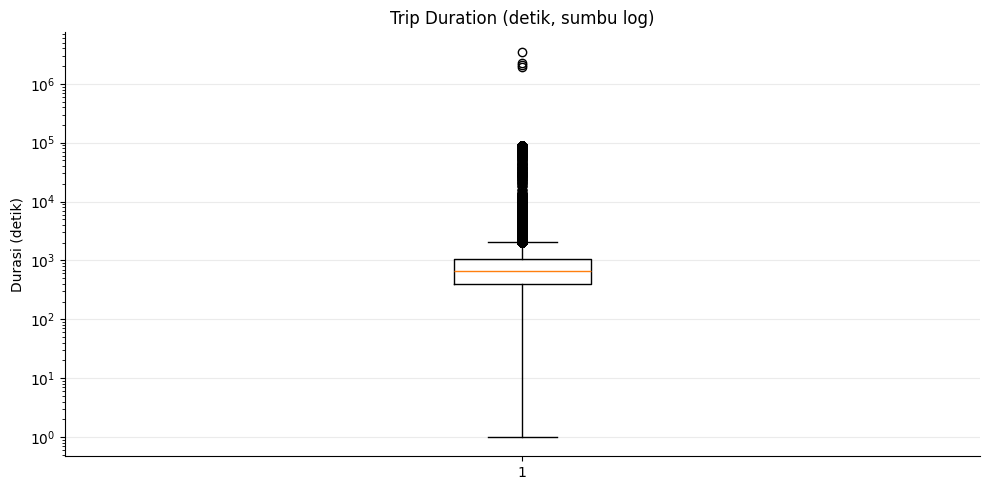

In [15]:
positive_duration = df.loc[df["trip_duration"] > 0, "trip_duration"].dropna()
display(positive_duration.describe(percentiles=[0.25, 0.5, 0.75, 0.9]).to_frame("durasi_detik"))
fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot(positive_duration, showfliers=True)
ax.set_yscale("log")
ax.set_title("Trip Duration (detik, sumbu log)")
ax.set_ylabel("Durasi (detik)")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

Boxplot menunjukkan sebaran durasi, tetapi batas IQR atas 2.092 detik (34 menit 52 detik),tetapi masih kurang kuat kalo disebutkan nilai diatasnya sebagai perjalanan yang salah atau salah catatan karena mungkin saja terjadi macet lalulintas atau rute yang memang benar2 jauh.Lalu IQR dipakai sebagai penanda statistik awal.

In [16]:
with measure("3. Outliers", "IQR dan flag statistik", len(df)):
    x_trip_duration = df["trip_duration"]
    q1, q3 = x_trip_duration.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    df["duration_iqr_flag"] = (x_trip_duration < lower) | (x_trip_duration > upper)
print("Batas IQR (detik):", lower, upper)
print("Kandidat IQR:", int(df["duration_iqr_flag"].sum()))
print("Batas bawah negatif: IQR tidak mendeteksi durasi positif yang terlalu pendek.")

Batas IQR (detik): -620.0 2092.0
Kandidat IQR: 74218
Batas bawah negatif: IQR tidak mendeteksi durasi positif yang terlalu pendek.


Selanjutnya gunakan kembali selisih timestamp, `distance_km`, dan `avg_speed_kmh` yang sudah dihitung memakai `haversine_km()` pada Erroneous.

### Interpretasi durasi ekstrem
IQR hanya penanda statistik, bukan batas maksimum perjalanan benar. Durasi beberapa jam ditinjau bersama jarak; durasi berhari-hari dengan perpindahan pendek lebih mencurigakan. Analisis Outliers memakai data setelah 42 record berflag kecepatan >300 km/jam dikeluarkan pada Erroneous.

## b) Coordinate Outlier

,pickup_longitude,dropoff_longitude,pickup_latitude,dropoff_latitude
count,1.458602e+06,1.458602e+06,1.458602e+06,1.458602e+06
mean,-7.397349e+01,-7.397339e+01,4.075092e+01,4.075181e+01
std,7.037000e-02,6.928769e-02,3.065101e-02,3.461839e-02
min,-1.219333e+02,-1.219333e+02,3.435970e+01,3.435970e+01
25%,-7.399187e+01,-7.399133e+01,4.073735e+01,4.073589e+01
50%,-7.398174e+01,-7.397975e+01,4.075410e+01,4.075452e+01
75%,-7.396733e+01,-7.396302e+01,4.076836e+01,4.076981e+01
max,-6.133553e+01,-6.133553e+01,4.391176e+01,4.391176e+01


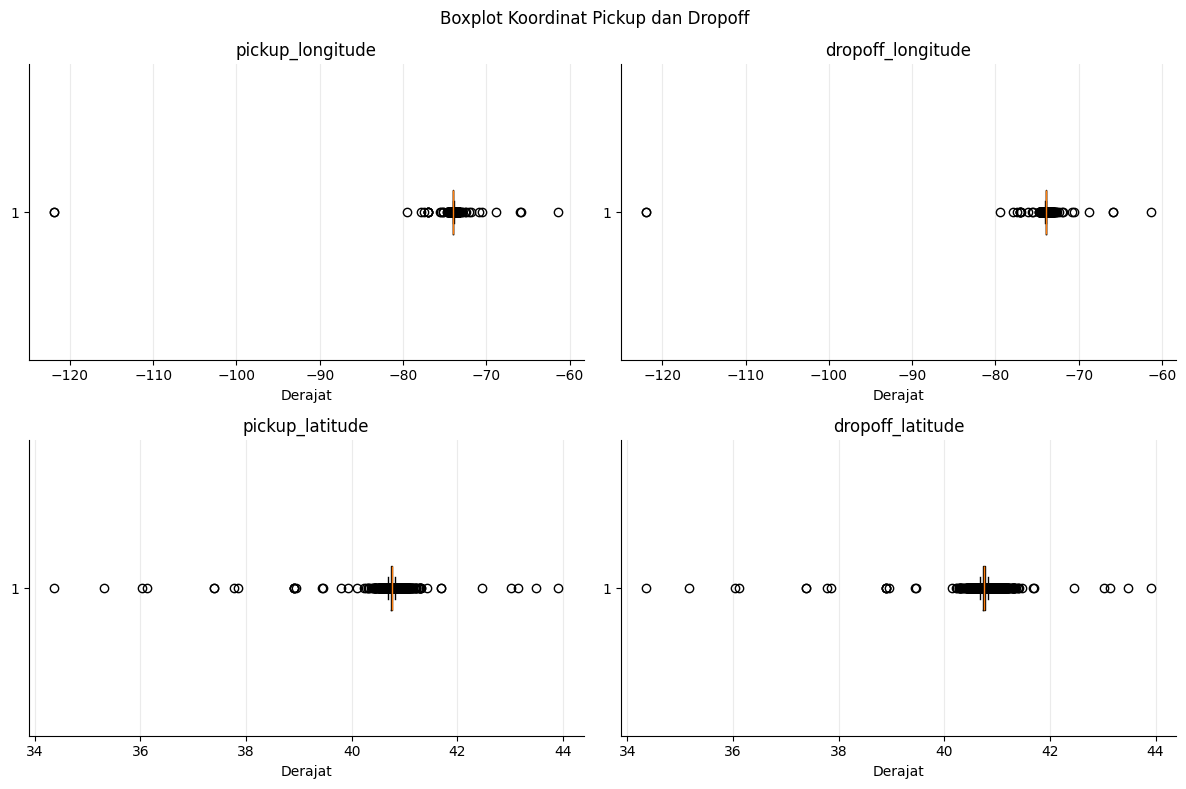

In [17]:
coordinate_columns = [
    "pickup_longitude", "dropoff_longitude",
    "pickup_latitude", "dropoff_latitude",
]
display(df[coordinate_columns].describe())
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, column in zip(axes.flat, coordinate_columns):
    values = df[column].dropna()
    ax.boxplot(values, orientation="horizontal", showfliers=True)
    ax.set_title(column)
    ax.set_xlabel("Derajat")
    ax.grid(axis="x", alpha=0.25)
fig.suptitle("Boxplot Koordinat Pickup dan Dropoff")
fig.tight_layout()
plt.show()

### Analisis boxplot koordinat

titik di luar whisker belum tentu berada di luar NYC. Untuk membuat flag lokasi, koordinat di luar rentang diberi `Y` agar ditinjau, bukan langsung dinyatakan salah.

Parameter pemeriksaan: longitude `-74.3` sampai `-73.65`, latitude `40.45` sampai `41.0`. Baris diberi `Y` jika pickup atau dropoff berada di luar rentang tersebut; selain itu `N`.

In [18]:
with measure("3. Outliers", "Screening bbox", len(df)):
    lon_min, lon_max = -74.3, -73.65
    lat_min, lat_max = 40.45, 41.0
    known_coordinates = df[coordinate_columns].notna().all(axis=1)
    inside_nyc = (
        df["pickup_longitude"].between(lon_min, lon_max)
        & df["dropoff_longitude"].between(lon_min, lon_max)
        & df["pickup_latitude"].between(lat_min, lat_max)
        & df["dropoff_latitude"].between(lat_min, lat_max)
    )
    df["coordinate_outlier_flag"] = np.select(
        [~known_coordinates, inside_nyc], ["Unknown", "N"], default="Y"
    )
display(df["coordinate_outlier_flag"].value_counts().to_frame("jumlah_trip"))
display(df.loc[df["coordinate_outlier_flag"].eq("Y"), [
    "id", *coordinate_columns, "coordinate_outlier_flag"
]].head(10))

,jumlah_trip
coordinate_outlier_flag,
N,1457844
Y,758


,id,pickup_longitude,dropoff_longitude,pickup_latitude,dropoff_latitude,coordinate_outlier_flag
115,id2358953,-73.870819,-73.857498,40.773739,41.017811,Y
986,id0015493,-74.005486,-73.643425,40.728619,40.670380,Y
991,id1859156,-73.969254,-73.593582,40.754047,41.043865,Y
1101,id3913560,-74.012657,-74.307762,40.702179,40.567341,Y
7371,id3502250,-73.874596,-73.612038,40.774082,40.659595,Y
9565,id0304778,-73.982925,-74.379631,40.761841,40.745274,Y
13006,id3022813,-73.558289,-73.558281,40.781223,40.781227,Y
14502,id1092161,-73.781792,-72.711395,40.644718,41.311520,Y
16751,id0633635,-73.994026,-73.930740,40.715553,41.086540,Y
17802,id3770021,-73.862038,-73.542152,40.764641,41.052258,Y


## c) Trip duration ekstrem vs lokasi NYC

,jumlah_trip,jumlah_outlier_durasi,persen_dari_semua_outlier,persen_outlier_dalam_kelompok
coordinate_outlier_flag,,,,
N,1457844,73800,99.44,5.06
Y,758,418,0.56,55.15
Unknown,0,0,0.00,NaN


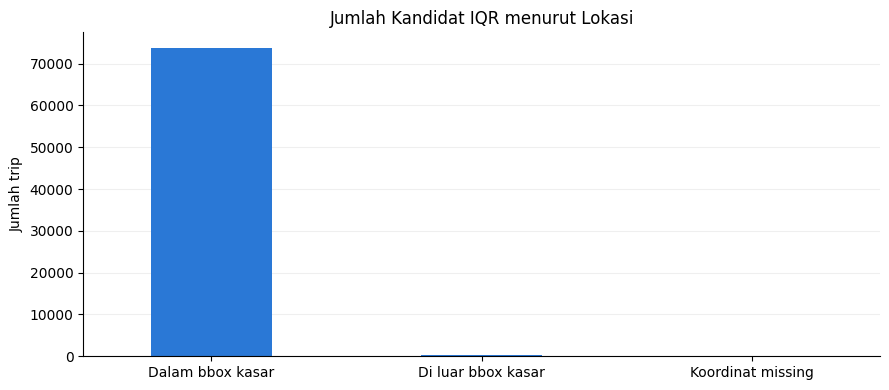

In [19]:
with measure("3. Outliers", "Perbandingan lokasi kandidat IQR", len(df)):
    location_summary = df.groupby("coordinate_outlier_flag").agg(
        jumlah_trip=("id", "size"),
        jumlah_outlier_durasi=("duration_iqr_flag", "sum"),
    ).reindex(["N", "Y", "Unknown"], fill_value=0)
    total_outliers = location_summary["jumlah_outlier_durasi"].sum()
    location_summary["persen_dari_semua_outlier"] = (
        location_summary["jumlah_outlier_durasi"] / total_outliers * 100
        if total_outliers else 0.0
    )
    location_summary["persen_outlier_dalam_kelompok"] = (
        location_summary["jumlah_outlier_durasi"]
        / location_summary["jumlah_trip"].replace(0, np.nan) * 100
    )
display(location_summary.round(2))

ax = location_summary["jumlah_outlier_durasi"].rename(index={
    "N": "Dalam bbox kasar", "Y": "Di luar bbox kasar", "Unknown": "Koordinat missing",
}).plot.bar(figsize=(9, 4), color=BLUE, width=0.45, rot=0)
ax.set(title="Jumlah Kandidat IQR menurut Lokasi", xlabel="", ylabel="Jumlah trip")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

berdasarkan grafik diatas, rentan outlier durasi masih di area wilayah NYC. Maka dari itu perlu kita lihat kebanyakan di beberapa km itu rata-rata menghabiskan durasi berapa.

**Batas interpretasi:** area di sini berarti bbox kasar, bukan batas resmi NYC. Jumlah outlier terbanyak bisa mengikuti ukuran kelompok. Untuk membandingkan kecenderungan, baca juga `persen_outlier_dalam_kelompok`. Median dan P90 per jarak dipakai sebagai konteks berikutnya, bukan batas validitas.

## d) Durasi perjalanan menurut jarak di dalam NYC

In [20]:
with measure("3. Outliers", "Kelompok jarak sampai 20 km", len(df)):
    inside_nyc = df["coordinate_outlier_flag"].eq("N")
    over_20_km = inside_nyc & df["distance_km"].gt(20)
    inside_distance = df.loc[
        inside_nyc & df["distance_km"].between(0, 20, inclusive="both")
    ].copy()
    inside_distance["distance_group"] = pd.cut(
        inside_distance["distance_km"],
        bins=[0, 0.5, 1, *range(2, 21)],
        labels=["0–0.5 km", "0.5–1 km"] + [f"{i}–{i+1} km" for i in range(1, 20)],
        right=True, include_lowest=True,
    )
    inside_distance["duration_hours"] = inside_distance["trip_duration"] / 3600
print("Trip di dalam bbox tetapi >20 km (di luar cakupan tabel):", int(over_20_km.sum()))
print("Trip berjarak nol dalam kelompok pertama:", int(inside_distance["distance_km"].eq(0).sum()))

Trip di dalam bbox tetapi >20 km (di luar cakupan tabel): 23382
Trip berjarak nol dalam kelompok pertama: 5801


In [21]:
with measure("3. Outliers", "Median dan P90 per jarak", len(inside_distance)):
    distance_duration_summary = inside_distance.groupby("distance_group", observed=False)["duration_hours"].agg(
        jumlah_trip="count", median_jam="median",
        persentil_90_jam=lambda values: values.quantile(0.90),
    )
display(distance_duration_summary.round(2))

,jumlah_trip,median_jam,persentil_90_jam
distance_group,,,
0–0.5 km,48706,0.05,0.19
0.5–1 km,197023,0.08,0.16
1–2 km,451215,0.13,0.24
2–3 km,265583,0.20,0.33
3–4 km,145238,0.25,0.41
4–5 km,88015,0.29,0.47
5–6 km,58343,0.33,0.52
6–7 km,40450,0.36,0.56
7–8 km,26818,0.38,0.59


Hasil ini menunjukkan durasi tipikal untuk kelompok jarak 0–0.5 km dan 4–5 km. Gunakan median sebagai gambaran perjalanan umum dan persentil 90 sebagai batas perjalanan lama yang masih terlihat pada 90% data di kelompok tersebut. Trip yang jauh melewati persentil 90 dapat ditinjau lebih lanjut

## e) Tinjau durasi paling ekstrem dan sangat pendek

Urutkan data sebelum memilih aturan mitigasi. Perhatikan kesenjangan durasi antarkasus, timestamp, dan jarak. Durasi mendekati 24 jam tetap perlu ditinjau.
Trip sangat pendek diperiksa terpisah karena batas bawah IQR negatif. Kecepatan berbasis garis lurus hanya indikator investigasi, bukan bukti penyebab kesalahan.

In [22]:
with measure("3. Outliers", "Investigasi durasi teratas dan terbawah", len(df)):
    top_duration = df.nlargest(10, "trip_duration")[[
        "id", "pickup_datetime", "dropoff_datetime", "trip_duration",
        "duration_from_time", "distance_km", "avg_speed_kmh",
    ]].copy()
    top_duration["durasi_hari"] = top_duration["trip_duration"] / 86400
    top_duration["rasio_ke_durasi_berikutnya"] = (
        top_duration["trip_duration"] / top_duration["trip_duration"].shift(-1)
    )
    shortest_duration = df.nsmallest(10, "trip_duration")[[
        "id", "trip_duration", "duration_from_time", "distance_km", "avg_speed_kmh",
    ]]
print("Durasi terbesar:")
display(top_duration.round(3))
print("Durasi terkecil:")
display(shortest_duration.round(3))

Durasi terbesar:


,id,pickup_datetime,dropoff_datetime,trip_duration,duration_from_time,distance_km,avg_speed_kmh,durasi_hari,rasio_ke_durasi_berikutnya
978383,id0053347,2016-02-13 22:46:52,2016-03-25 18:18:14,3526282,3526282.0,19.901,0.020,40.813,1.583
924150,id1325766,2016-01-05 06:14:15,2016-01-31 01:01:07,2227612,2227612.0,1.635,0.003,25.783,1.087
680594,id0369307,2016-02-13 22:38:00,2016-03-08 15:57:38,2049578,2049578.0,5.982,0.011,23.722,1.057
355003,id1864733,2016-01-05 00:19:42,2016-01-27 11:08:38,1939736,1939736.0,20.149,0.037,22.451,22.453
1234291,id1942836,2016-02-15 23:18:06,2016-02-16 23:17:58,86392,86392.0,20.643,0.860,1.000,1.000
295382,id0593332,2016-05-31 13:00:39,2016-06-01 13:00:30,86391,86391.0,21.117,0.880,1.000,1.000
73816,id0953667,2016-05-06 00:00:10,2016-05-07 00:00:00,86390,86390.0,2.004,0.084,1.000,1.000
59891,id2837671,2016-06-30 16:37:52,2016-07-01 16:37:39,86387,86387.0,6.204,0.259,1.000,1.000
1360439,id1358458,2016-06-23 16:01:45,2016-06-24 16:01:30,86385,86385.0,17.292,0.721,1.000,1.000
753765,id2589925,2016-05-17 22:22:56,2016-05-18 22:22:35,86379,86379.0,9.825,0.409,1.000,NaN


Durasi terkecil:


,id,trip_duration,duration_from_time,distance_km,avg_speed_kmh
35196,id2536510,1,1.0,0.009,32.266
207497,id1520236,1,1.0,0.001,2.314
279493,id1491861,1,1.0,0.000,1.527
285635,id0075470,1,1.0,0.000,0.000
311745,id2959956,1,1.0,0.020,71.606
346102,id2375785,1,1.0,0.010,35.927
346959,id1171557,1,1.0,0.000,0.000
404610,id3686648,1,1.0,0.003,9.745
451396,id2836747,1,1.0,0.000,0.000
533799,id3563137,1,1.0,0.002,7.667


### Interpretasi kasus ekstrem

Empat trip berlangsung sekitar **22–41 hari** dengan perpindahan **1,6–20,1 km**; durasi terbesar berikutnya kurang dari satu hari. Tabel jarak 0–20 km tidak digunakan untuk menilai record 20,15 km.

Kesimpulan: empat record itu tidak representatif untuk analisis perjalanan taksi biasa. Penyebabnya belum diketahui; tidak diklaim terbukti mustahil. Trip mendekati 24 jam, trip pendek, dan titik di luar bbox tetap kandidat tinjauan, bukan otomatis dihapus.

## f) Mitigasi akhir Outliers

Keluarkan hanya empat ID yang sudah diperiksa dari salinan analisis, bukan semua trip yang melewati IQR atau 24 jam. Aturan ini keputusan khusus dataset ini, bukan aturan umum taksi. Simpan `excluded_outliers` beserta alasan; `df_raw` tetap utuh. Tidak dilakukan clipping target atau penggantian durasi dengan median karena nilai benar tidak diketahui.

In [23]:
with measure("3. Outliers", "Mitigasi empat kasus hasil tinjauan", len(df)):
    reviewed_ids = {"id0053347", "id1325766", "id0369307", "id1864733"}
    remove_outlier = df["id"].isin(reviewed_ids)
    reviewed = df.loc[remove_outlier]
    if (len(reviewed) != 4 or reviewed["id"].nunique() != 4
            or set(df.nlargest(4, "trip_duration")["id"]) != reviewed_ids
            or not reviewed["trip_duration"].between(22 * 86400, 42 * 86400).all()):
        raise ValueError("Empat kasus tidak sesuai bukti sebelumnya; tinjau ulang sebelum menghapus.")
    excluded_outliers = reviewed.copy()
    excluded_outliers["reason"] = "Durasi 22–41 hari; tidak representatif untuk perjalanan taksi biasa"
    df_clean = df.loc[~remove_outlier].copy()
    outlier_impact = pd.DataFrame({
        "tahap": ["Sebelum mitigasi outlier", "Dikeluarkan setelah tinjauan", "Sesudah mitigasi outlier"],
        "jumlah_trip": [len(df), len(excluded_outliers), len(df_clean)],
    })
display(excluded_outliers[["id", "trip_duration", "distance_km", "reason"]])
display(outlier_impact)

,id,trip_duration,distance_km,reason
355003,id1864733,1939736,20.148664,Durasi 22–41 hari; tidak representatif untuk p...
680594,id0369307,2049578,5.982487,Durasi 22–41 hari; tidak representatif untuk p...
924150,id1325766,2227612,1.635128,Durasi 22–41 hari; tidak representatif untuk p...
978383,id0053347,3526282,19.900661,Durasi 22–41 hari; tidak representatif untuk p...


,tahap,jumlah_trip
0,Sebelum mitigasi outlier,1458602
1,Dikeluarkan setelah tinjauan,4
2,Sesudah mitigasi outlier,1458598


# 4. Noise
Noise pengukuran adalah gangguan pada nilai yang dicatat, misalnya posisi GPS bergeser dari posisi sebenarnya. Bagian ini membahas apakah data yang tersedia cukup untuk memeriksa gangguan tersebut.

### Analisis dan keterbatasan data
Trip satu detik dengan perpindahan 133 m dan 231 m mencurigakan, tetapi belum membuktikan noise GPS. Dataset hanya memiliki lokasi dan waktu pickup–dropoff, tanpa lintasan GPS atau posisi acuan untuk memastikan sumber kesalahan. Karena bukti belum cukup, tidak dilakukan koreksi tambahan pada bagian Noise. Kasus ekstrem sudah ditangani di Erroneous.

### Keputusan mitigasi Noise
**Noise pengukuran belum dapat dikonfirmasi; bukan berarti data terbukti bebas noise.** Tidak mengubah koordinat/waktu atau menghapus record pada bagian ini. Kasus jarak–durasi ekstrem sudah ditangani di Erroneous; tidak dihitung ulang sebagai noise. Koreksi memerlukan bukti tambahan, bukan pembulatan atau smoothing yang ditebak.

# 5. Missing values
Periksa nilai hilang pada train dan test. Kolom target yang memang tidak disediakan pada test bukan missing per baris; kegagalan parsing sudah diperiksa pada bagian Formatting.

In [24]:
with measure("5. Missing", "Audit missing train dan test", len(df_raw) + len(df_test)):
    missing_by_column = {"train": df_raw.isna().sum(), "test": df_test.isna().sum()}
    missing_original = pd.DataFrame([
        {"dataset": name, "total_sel_missing": int(counts.sum()),
         "kolom_dengan_missing": int(counts.gt(0).sum())}
        for name, counts in missing_by_column.items()
    ]).set_index("dataset")
display(missing_original)
for name, counts in missing_by_column.items():
    if counts.gt(0).any():
        print(name)
        display(counts.loc[counts.gt(0)].to_frame("jumlah_missing"))

,total_sel_missing,kolom_dengan_missing
dataset,,
train,0,0
test,0,0


### Interpretasi dan mitigasi Missing values
Tidak ditemukan nilai hilang pada train maupun test. **Diagnosis MCAR/MAR dan imputasi tidak diperlukan**; tidak ada record yang dihapus atau nilai yang diganti pada tahap ini.

# 6. Duplicate records

### Definisi dan deteksi
Periksa dua hal: ID berulang dan record dengan **semua kolom asli selain `id` identik**. Flag serta fitur turunan tidak ikut menentukan kesamaan. Vendor dan waktu pickup saja tidak cukup menjadi kunci unik.

Record identik dengan ID berbeda masih mungkin merupakan kejadian berbeda; tanpa sumber tambahan, duplikasi peristiwa tidak dapat dibuktikan. Untuk salinan analisis ini, digunakan kebijakan eksplisit: satu observasi per kombinasi atribut asli identik. Tinjau contoh sebelum menerapkan kebijakan.

In [25]:
with measure("6. Duplicates", "Deteksi ID dan atribut identik", len(df_clean)):
    duplicate_columns = [c for c in original_columns if c != "id"]
    duplicate_id = df_clean["id"].duplicated(keep=False)
    duplicate_members = df_clean.duplicated(subset=duplicate_columns, keep=False)
    duplicate_extra = df_clean.duplicated(subset=duplicate_columns, keep="first")
    duplicate_summary = pd.Series({
        "Baris dengan ID berulang": duplicate_id.sum(),
        "Seluruh anggota kelompok atribut identik": duplicate_members.sum(),
        "Salinan ekstra yang akan dikeluarkan": duplicate_extra.sum(),
    })
    duplicate_examples = df_clean.loc[duplicate_members, original_columns].sort_values(
        duplicate_columns
    ).head(10)
display(duplicate_summary.to_frame("jumlah"))
display(duplicate_examples)

,jumlah
Baris dengan ID berulang,0
Seluruh anggota kelompok atribut identik,14
Salinan ekstra yang akan dikeluarkan,7


,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
1135493,id3603778,2,2016-01-21 12:04:53,2016-01-21 13:35:06,3,-73.800667,40.645954,-73.985809,40.763363,N,5413
1422084,id0978620,2,2016-01-21 12:04:53,2016-01-21 13:35:06,3,-73.800667,40.645954,-73.985809,40.763363,N,5413
212931,id2805144,2,2016-02-16 21:36:35,2016-02-16 21:37:06,2,-74.008034,40.723553,-74.008034,40.723553,N,31
1333727,id0133335,2,2016-02-16 21:36:35,2016-02-16 21:37:06,2,-74.008034,40.723553,-74.008034,40.723553,N,31
403880,id2290238,2,2016-03-05 18:22:41,2016-03-05 18:25:10,2,-73.997292,40.691071,-73.999428,40.683388,N,149
840075,id0946562,2,2016-03-05 18:22:41,2016-03-05 18:25:10,2,-73.997292,40.691071,-73.999428,40.683388,N,149
445735,id1067917,2,2016-03-06 10:06:31,2016-03-07 09:59:05,4,-73.997055,40.737183,-73.991913,40.734577,N,85954
728313,id2386705,2,2016-03-06 10:06:31,2016-03-07 09:59:05,4,-73.997055,40.737183,-73.991913,40.734577,N,85954
1196478,id1417596,2,2016-03-12 16:41:35,2016-03-12 16:47:54,1,-73.974533,40.742298,-73.979507,40.750549,N,379
1407182,id0146524,2,2016-03-12 16:41:35,2016-03-12 16:47:54,1,-73.974533,40.742298,-73.979507,40.750549,N,379


### Interpretasi dan mitigasi Duplicates
Jumlah anggota kelompok berbeda dengan salinan ekstra: kelompok dua baris menyumbang dua anggota, tetapi hanya satu salinan dikeluarkan. Baca jumlah aktual pada tabel setelah mitigasi sebelumnya; pertahankan kemunculan pertama sesuai urutan CSV. ID berbeda tidak menentukan record mana yang lebih benar.

Simpan salinan ekstra untuk audit. Jika ID sama memiliki atribut berbeda, hentikan mitigasi otomatis dan investigasi konflik. Deduplikasi dilakukan sebelum split pemodelan agar salinan identik tidak tersebar di train/validasi.

In [26]:
with measure("6. Duplicates", "Mitigasi salinan ekstra", len(df_clean)):
    unique_attributes = df_clean.drop_duplicates(subset=original_columns)
    if unique_attributes["id"].duplicated().any():
        raise ValueError("ID berulang memiliki atribut berbeda; investigasi sebelum deduplikasi.")
    excluded_duplicates = df_clean.loc[duplicate_extra].copy()
    excluded_duplicates["reason"] = "Salinan ekstra: seluruh atribut asli selain id identik"
    df_final = df_clean.loc[~duplicate_extra].copy()
print("Dikeluarkan:", len(excluded_duplicates), "| Tersisa:", len(df_final))
print("Salinan ekstra sesudah mitigasi:", int(df_final.duplicated(subset=duplicate_columns).sum()))

Dikeluarkan: 7 | Tersisa: 1458591
Salinan ekstra sesudah mitigasi: 0


# 7. Ringkasan dampak mitigasi
Tabel menghitung pengeluaran baris berurutan, tanpa menghitung ulang record yang sama. `df_raw` dan empat tabel `excluded_*` menjaga jejak audit. Record berflag kecepatan >300 km/jam dikeluarkan dari salinan analisis; kandidat >150 hingga ≤300 km/jam tetap ditinjau. Noise dibahas berdasarkan temuan Erroneous dan keterbatasan bukti, tanpa koreksi tambahan; Missing diaudit tanpa imputasi. `df_final` bukan jaminan semua masalah telah selesai. Belum ada CSV diekspor otomatis.

In [27]:
mitigation_summary = pd.DataFrame([
    ["Data mentah", 0, len(df_raw), "Sumber tetap utuh"],
    ["1. Formatting", 0, len(df_raw), "Normalisasi tanggal; gagal validasi ditangani pada bagian 2"],
    ["2a. Domain/format", len(excluded_invalid), len(df_raw) - len(excluded_invalid), "Pemisahan pelanggaran domain/format"],
    ["2b. Jarak–durasi", len(excluded_speed), len(df), "Record berflag >300 km/jam dikeluarkan; kandidat >150 yang tersisa tetap ditinjau"],
    ["3. Outliers", len(excluded_outliers), len(df_clean), "Empat kasus hasil tinjauan; kandidat lain dipertahankan"],
    ["4. Noise", 0, len(df_clean), "Analisis temuan dan keterbatasan bukti; tanpa koreksi tambahan"],
    ["5. Missing", 0, len(df_clean), "Tidak ditemukan missing; tanpa imputasi"],
    ["6. Duplicates", len(excluded_duplicates), len(df_final), "Satu record per kombinasi atribut asli selain id"],
], columns=["tahap", "baris_dikeluarkan", "baris_tersisa", "tindakan"])
excluded_tables = [excluded_invalid, excluded_speed, excluded_outliers, excluded_duplicates]
assert len(df_raw) == len(df_final) + sum(len(table) for table in excluded_tables)
all_excluded_indices = [index for table in excluded_tables for index in table.index]
assert len(all_excluded_indices) == len(set(all_excluded_indices))
assert set(df_final.index).isdisjoint(all_excluded_indices)
assert not df_final.duplicated(subset=duplicate_columns).any()
display(mitigation_summary)
print("Pemeriksaan konservasi jumlah baris dan eksklusi tanpa tumpang tindih: lulus.")
print("Flag >150 km/jam yang masih perlu ditinjau pada data akhir:", int(df_final["speed_review_flag"].sum()))
print("Record berflag >300 km/jam disimpan terpisah:", len(excluded_speed))

,tahap,baris_dikeluarkan,baris_tersisa,tindakan
0,Data mentah,0,1458644,Sumber tetap utuh
1,1. Formatting,0,1458644,Normalisasi tanggal; gagal validasi ditangani ...
2,2a. Domain/format,0,1458644,Pemisahan pelanggaran domain/format
3,2b. Jarak–durasi,42,1458602,Record berflag >300 km/jam dikeluarkan; kandid...
4,3. Outliers,4,1458598,Empat kasus hasil tinjauan; kandidat lain dipe...
5,4. Noise,0,1458598,Analisis temuan dan keterbatasan bukti; tanpa ...
6,5. Missing,0,1458598,Tidak ditemukan missing; tanpa imputasi
7,6. Duplicates,7,1458591,Satu record per kombinasi atribut asli selain id


Pemeriksaan konservasi jumlah baris dan eksklusi tanpa tumpang tindih: lulus.
Flag >150 km/jam yang masih perlu ditinjau pada data akhir: 56
Record berflag >300 km/jam disimpan terpisah: 42


In [28]:
fig = go.Figure(go.Bar(
    x=mitigation_summary.loc[1:, "baris_dikeluarkan"],
    y=mitigation_summary.loc[1:, "tahap"], orientation="h", width=0.4,
    marker=dict(color=BLUE, cornerradius=4),
    text=mitigation_summary.loc[1:, "baris_dikeluarkan"], textposition="outside",
    hovertemplate="%{y}<br>%{x:,} record dikeluarkan<extra></extra>",
))
fig.update_xaxes(rangemode="tozero")
fig.update_yaxes(autorange="reversed")
show_quality_chart(fig, "Dampak mitigasi · pengeluaran record per tahap tanpa tumpang tindih",
                   "Jumlah record dikeluarkan dari salinan analisis", "Tahap", height=480)

# 8. Waktu eksekusi dan kompleksitas

### Pengukuran aktual
Waterfall berikut menyerupai timeline network: posisi kiri = mulai langkah, panjang batang = durasi komputasi. Pengukuran memakai `perf_counter()` pada blok `measure`, bukan waktu CPU murni. Semua langkah berjalan **sekuensial**, bukan paralel.

In [29]:
timing_steps = pd.DataFrame(timing_records).sort_values("start_s").reset_index(drop=True)
timing_steps["mulai_relatif_s"] = timing_steps["start_s"] - timing_steps["start_s"].min()
timing_steps["selesai_relatif_s"] = timing_steps["mulai_relatif_s"] + timing_steps["duration_s"]
timing_sections = timing_steps.groupby("section", sort=False).agg(
    jumlah_langkah=("step", "size"), komputasi_terukur_s=("duration_s", "sum")
)
timing_sections["persen_waktu_terukur"] = (
    timing_sections["komputasi_terukur_s"] / timing_steps["duration_s"].sum() * 100
)
display(timing_sections.round(4))
display(timing_steps[["section", "step", "rows", "mulai_relatif_s", "duration_s", "selesai_relatif_s"]].round(4))
print(f"Total blok komputasi: {timing_steps['duration_s'].sum():.3f} detik")
print(f"Rentang timeline: {timing_steps['selesai_relatif_s'].max():.3f} detik")

,jumlah_langkah,komputasi_terukur_s,persen_waktu_terukur
section,,,
1. Formatting,1,1.0316,13.4782
2. Erroneous,6,1.1902,15.5492
3. Outliers,7,2.1346,27.8877
5. Missing,1,0.3724,4.8648
6. Duplicates,2,2.9254,38.2201


,section,step,rows,mulai_relatif_s,duration_s,selesai_relatif_s
0,1. Formatting,Parsing dan normalisasi,1458644,0.0000,1.0316,1.0316
1,2. Erroneous,Validasi domain,1458644,1.0695,0.0554,1.1250
2,2. Erroneous,Flag domain dan salinan analisis,1458644,1.1334,0.3553,1.4887
3,2. Erroneous,Konsistensi waktu dan haversine,1458644,1.5218,0.2359,1.7577
4,2. Erroneous,Sampel visualisasi jarak durasi,1458644,1.7991,0.1444,1.9435
5,2. Erroneous,Investigasi durasi singkat,1458644,5.5540,0.0896,5.6436
6,2. Erroneous,Flag dan seleksi kombinasi jarak durasi,1458644,5.7516,0.3094,6.0610
7,3. Outliers,IQR dan flag statistik,1458602,6.7540,0.0365,6.7905
8,3. Outliers,Screening bbox,1458602,7.8621,0.1346,7.9968
9,3. Outliers,Perbandingan lokasi kandidat IQR,1458602,8.2497,0.0931,8.3429


Total blok komputasi: 7.654 detik
Rentang timeline: 13.784 detik


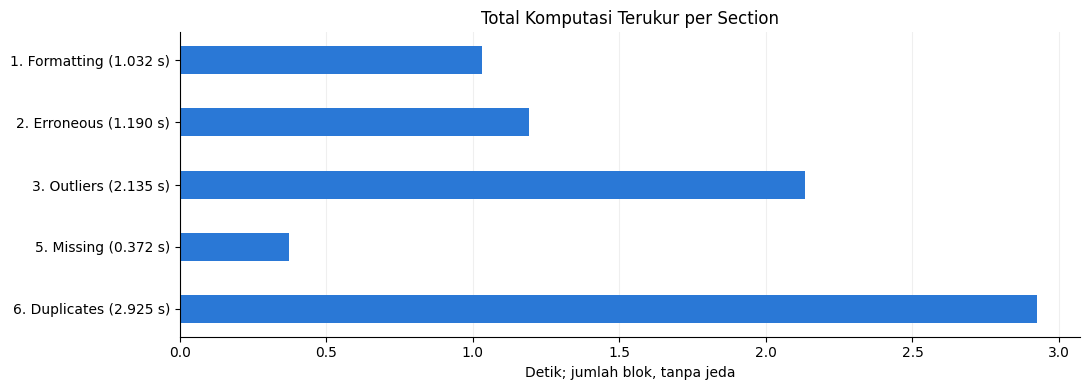

In [30]:
fig, ax = plt.subplots(figsize=(11, 4))
labels = [f"{name} ({seconds:.3f} s)" for name, seconds in
          timing_sections["komputasi_terukur_s"].items()]
ax.barh(labels, timing_sections["komputasi_terukur_s"], color=BLUE, height=0.45)
ax.invert_yaxis()
ax.set(title="Total Komputasi Terukur per Section", xlabel="Detik; jumlah blok, tanpa jeda")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

In [31]:
timing_labels = timing_steps["section"] + " | " + timing_steps["step"]
fig = go.Figure(go.Bar(
    x=timing_steps["duration_s"], base=timing_steps["mulai_relatif_s"],
    y=timing_labels, orientation="h", width=0.45, marker=dict(color=BLUE, cornerradius=4),
    customdata=timing_steps[["mulai_relatif_s", "selesai_relatif_s", "rows"]].to_numpy(),
    hovertemplate="%{y}<br>Mulai %{customdata[0]:.3f} s<br>Durasi %{x:.3f} s"
                  "<br>Selesai %{customdata[1]:.3f} s<br>Baris %{customdata[2]:,.0f}<extra></extra>",
))
fig.update_yaxes(autorange="reversed")
show_quality_chart(fig, "Waterfall komputasi aktual · sekuensial, jeda tidak dihitung sebagai komputasi",
                   "Detik sejak blok pertama", "Langkah", height=max(550, 27 * len(timing_steps) + 170))